# 3.2 Live OpenMM Practical: Simulating Protein Folding

*Adapted from Dr Eleanor Jayawant's Mitchell Lab MD practical (`MitchellLabTeachingMD`) and `klyshko/md_python`.*

In this live **Python** practical, we use **[OpenMM](https://openmm.org/)** to simulate an all-atom **200 picosecond** molecular dynamics trajectory of fully extended **polyalanine** (`polyALA.pdb`) at $T = 300\text{ K}$ — and watch whether it spontaneously folds into an **$\alpha$-helix**!

**The 7-Step Molecular Dynamics Workflow:**
1. **Load initial coordinates** of protein atoms from a `.pdb` file.
2. **Choose force field parameters** (`amber10.xml`).
3. **Set experimental conditions:** temperature ($300\text{ K}$), friction coefficient, time step ($2\text{ fs}$), and duration ($200\text{ ps}$).
4. **Choose an integrator** (Langevin thermostat solving Newton's equations of motion).
5. **Minimise energy & run the simulation**, saving frames to a `.dcd` trajectory file.
6. **Visualise the 3D folding trajectory** interactively.
7. **Quantitatively analyse the trajectory** (end-to-end distance & Ramachandran $\phi/\psi$ plot).

Click **⚡ Activate Live Editable Python Cells** above to run, modify parameters, and explore bonus experiments live! You do not need to write any code from scratch — just click **Run** (or press `Shift + Enter`) on each cell in turn.

## Step 1: Import Python MD Libraries & Starter Files

We import:
- **`openmm`** — molecular dynamics simulation engine
- **`MDAnalysis`** — trajectory & dihedral angle analysis
- **`numpy` & `matplotlib`** — numerical computing and plotting
- **`md_helpers`** — interactive 3D structure/trajectory viewers & custom name-peptide builder

In [1]:
import os
import sys
import warnings
from sys import stdout

warnings.filterwarnings("ignore")

# Locate the Molecular Dynamics workspace folder (works in live containers and local checkouts)
for candidate in ("/home/jovyan/work/MD", "MD", "tutorials/MD", "../../tutorials/MD"):
    if os.path.isdir(candidate):
        os.chdir(candidate)
        break

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from openmm.app import (
    CutoffNonPeriodic,
    DCDReporter,
    ForceField,
    PDBFile,
    Simulation,
    StateDataReporter,
)
from openmm import LangevinIntegrator
from openmm.unit import kelvin, picosecond, picoseconds
import MDAnalysis as mda
from MDAnalysis.analysis import dihedrals
import numpy as np
import matplotlib.pyplot as plt
from md_helpers import view_structure, view_trajectory, build_name_peptide

# Preloaded starter PDB files
pdb0_file = "data/villin_water.pdb"
pdb1_file = "data/polyALA.pdb"
pdb2_file = "data/polyGLY.pdb"
pdb3_file = "data/polyGV.pdb"

print("OpenMM & MDAnalysis ready!")

OpenMM & MDAnalysis ready!


## Step 2: Inspect the Starting Extended Polyalanine (`polyALA.pdb`)

Before running our simulation, let's look at `polyALA.pdb` at $t = 0\text{ ps}$. Notice that all 25 Alanine residues start in a completely stretched, flat conformation (~87 Å from N-terminus to C-terminus).

In [2]:
view_structure(
    pdb1_file,
    style="cartoon+stick",
    color="spectrum",
    title="Starting Extended Polyalanine — polyALA.pdb (t = 0 ps)",
)

## Step 3: Run a 200 ps MD Simulation of Polyalanine Folding

Now we run a **200 picosecond** simulation (100,000 steps of $\Delta t = 0.002\text{ ps} = 2\text{ fs}$) in vacuo at **$T = 300\text{ K}$** using the **AMBER10** force field (`amber10.xml`) and a **Langevin thermostat**.

*(This runs ~100,000 integration steps live on the server and takes roughly 45–60 seconds — watch the live progress table print step number, potential energy, and temperature!)*

:::{tip} Parameters You Can Experiment With Later
- Try changing `pdb_file = pdb1_file` to `pdb2_file` (`polyGLY.pdb`) or `pdb3_file` (`polyGV.pdb`).
- Try changing `temperature = 300 * kelvin` to `100 * kelvin` (very cold) or `600 * kelvin` (very hot!).
- Try changing `sim_length_ps = 200` (e.g., `100` for faster tests or `300` for longer folding).
:::

In [3]:
# === Editable experiment parameters ===
pdb_file = pdb1_file              # Try pdb2_file (polyGLY) or pdb3_file (polyGV)
traj_file = "data/polyALA_traj.dcd"
temperature = 300 * kelvin        # Try 100 * kelvin or 600 * kelvin!
frictionCoeff = 1 / picosecond
time_step = 0.002 * picoseconds   # 2 femtoseconds
sim_length_ps = 200               # Total simulation length in picoseconds
total_steps = int(sim_length_ps * picoseconds / time_step)

# 1. Load initial coordinates
pdb = PDBFile(pdb_file)

# 2. Choose force field parameters
ff = ForceField("amber10.xml")
system = ff.createSystem(pdb.topology, nonbondedMethod=CutoffNonPeriodic)

# 3. Choose an algorithm (Langevin integrator = NVT thermostat)
integrator = LangevinIntegrator(temperature, frictionCoeff, time_step)
integrator.setRandomNumberSeed(42)  # Remove or change this number for independent random runs

# 4. Create simulation object & minimise energy to remove steric clashes
simulation = Simulation(pdb.topology, system, integrator)
simulation.context.setPositions(pdb.positions)
simulation.minimizeEnergy()

# 5. Attach reporters (save DCD trajectory every 1,000 steps = 2 ps; print progress every 10,000 steps)
simulation.reporters.append(DCDReporter(traj_file, 1000))
simulation.reporters.append(
    StateDataReporter(
        stdout,
        10000,
        step=True,
        potentialEnergy=True,
        temperature=True,
        progress=True,
        totalSteps=total_steps,
    )
)

# 6. Run!
simulation.step(total_steps)
print("Simulation complete! Trajectory saved to:", traj_file)

#"Progress (%)","Step","Potential Energy (kJ/mole)","Temperature (K)"


10.0%,10000,5074.179681744599,297.34159508404423


20.0%,20000,5124.366927078454,294.13429689632864


30.0%,30000,5191.84728180194,297.7177851792174


40.0%,40000,5184.394581875794,325.75888501002214


50.0%,50000,5135.430597386026,303.0179139333305


... (2 outputs left out)

80.0%,80000,5018.374137532998,315.96787887577966


90.0%,90000,4954.78074438719,274.236899935577


100.0%,100000,4884.953627804658,284.91953601974734


Simulation complete! Trajectory saved to: data/polyALA_traj.dcd


## Step 4: Watch Your 3D Folding Trajectory Movie!

Click **▶ Play** below (or drag the frame slider from `0 ps` to `200 ps`) to watch your polyalanine chain fold in real time! You can rotate the molecule while the movie is playing and toggle between **Cartoon**, **Cartoon + Sticks**, and **Sticks**.

In [4]:
view_trajectory(
    pdb_file,
    traj_file,
    stride=2,
    total_ps=sim_length_ps,
    style="cartoon+stick",
    title=f"{os.path.basename(pdb_file)} Folding at {int(temperature.value_in_unit(kelvin))} K (0–{sim_length_ps} ps)",
)

## Step 5: Trajectory Analysis 1 — End-to-End Distance

Let's quantify how much the peptide compacts as it folds! We compute the Euclidean distance (in Ångströms) between the **N-terminal nitrogen** (`resid 1 and name N`) and the **C-terminal carbon** (last residue, `name C`) at every saved trajectory frame.

Frames analysed      : 100 (residues 1 to 25)
Initial end-to-end   : 87.3 Å
Final end-to-end     : 45.9 Å (minimum: 43.1 Å)


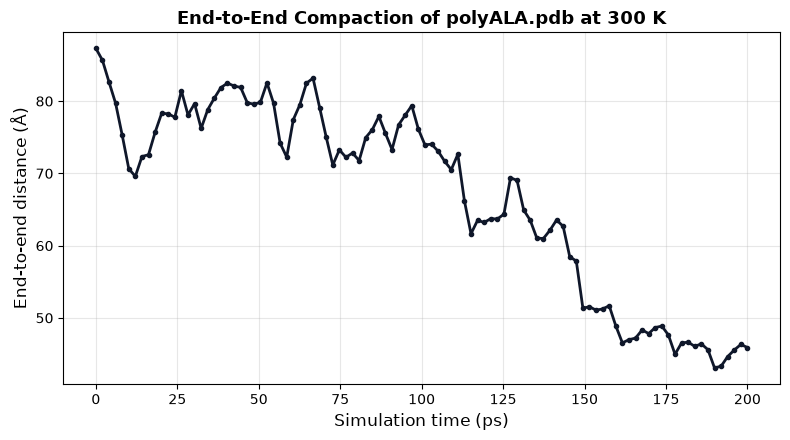

In [5]:
u = mda.Universe(pdb_file, traj_file)
last_resid = int(u.residues[-1].resid)

N_terminus = u.select_atoms("resid 1 and name N")
C_terminus = u.select_atoms(f"resid {last_resid} and name C")

dist = []
for frame in u.trajectory:
    dist.append(np.linalg.norm(N_terminus.positions - C_terminus.positions))
dist = np.array(dist)
times_ps = np.linspace(0, sim_length_ps, len(dist))

print(f"Frames analysed      : {len(dist)} (residues 1 to {last_resid})")
print(f"Initial end-to-end   : {dist[0]:.1f} Å")
print(f"Final end-to-end     : {dist[-1]:.1f} Å (minimum: {dist.min():.1f} Å)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(times_ps, dist, "-o", color="#0f172a", markersize=3, linewidth=2)
ax.set_xlabel("Simulation time (ps)", fontsize=12)
ax.set_ylabel("End-to-end distance (Å)", fontsize=12)
ax.set_title(
    f"End-to-End Compaction of {os.path.basename(pdb_file)} at {int(temperature.value_in_unit(kelvin))} K",
    fontsize=13,
    fontweight="bold",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 6: Trajectory Analysis 2 — Ramachandran Plot ($\phi$ vs $\psi$)

To verify **which** secondary structure formed, we plot the backbone dihedral angles $(\phi, \psi)$ for every interior residue across:
- **First 30% of frames (black dots):** Early in the simulation (starting near the extended / $\beta$ region)
- **Last 30% of frames (blue dots):** Late in the simulation (clustering tightly into the right-handed **$\alpha$-helix** region near $\phi \approx -60^\circ,\ \psi \approx -45^\circ$!)

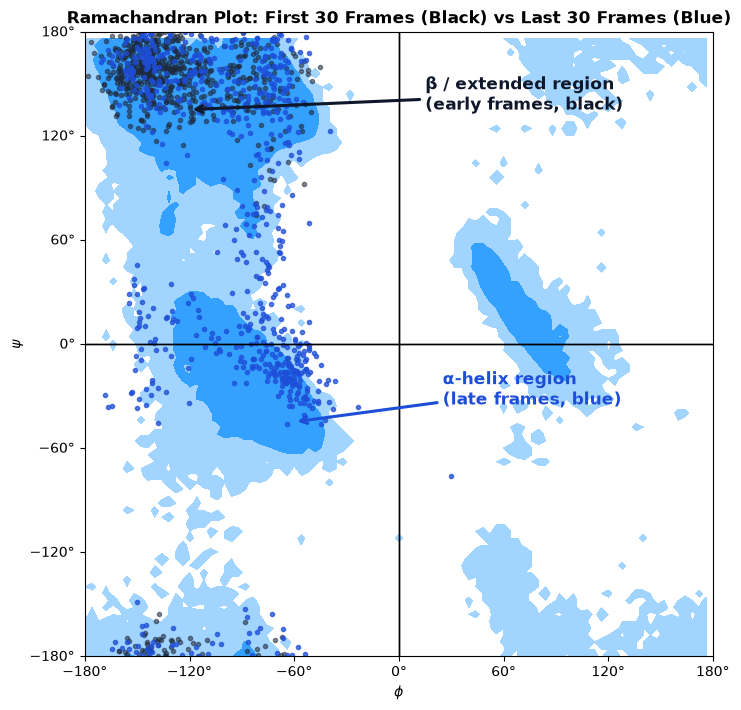

In [6]:
n_frames = len(u.trajectory)
early_stop = max(2, int(0.30 * n_frames))
late_start = min(n_frames - 2, int(0.70 * n_frames))

ram_early = dihedrals.Ramachandran(u).run(start=0, stop=early_stop)
ram_late = dihedrals.Ramachandran(u).run(start=late_start, stop=n_frames)

fig, ax = plt.subplots(figsize=(7.5, 7.2))
ram_early.plot(ax=ax, color="#1e293b", marker=".", alpha=0.55, ref=True)
ram_late.plot(ax=ax, color="#1d4ed8", marker=".", alpha=0.75, ref=False)

# Annotate key secondary-structure regions
ax.annotate(
    "α-helix region\n(late frames, blue)",
    xy=(-60, -45),
    xytext=(25, -35),
    color="#1d4ed8",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="#1d4ed8", lw=2.2),
)
ax.annotate(
    "β / extended region\n(early frames, black)",
    xy=(-120, 135),
    xytext=(15, 135),
    color="#0f172a",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="#0f172a", lw=2.2),
)
ax.set_title(
    f"Ramachandran Plot: First {early_stop} Frames (Black) vs Last {n_frames - late_start} Frames (Blue)",
    fontsize=12.5,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

## Step 7: Bonus Activity — Simulate a Peptide Spelling Your Own Name!

Want to test how a **heterogeneous sequence** with charged, polar, and bulky sidechains behaves compared to uniform polyalanine?

Change `MY_NAME` below to **your own name** (or try `"ELEANOR"`, `"SIMON"`, `"LYMPHOMA"`, or `"ALZHEIMER"`), and run a quick **40 ps** OpenMM simulation! Because `build_name_peptide(...)` adds exact `amber10.xml` hydrogens automatically, **any name simulates cleanly** with zero force-field errors!

In [7]:
MY_NAME = "ELEANOR"     # <-- Change to your own name!
name_sim_ps = 40        # Quick 40 ps demo (increase to 150-200 ps for longer folding!)
name_temp = 300 * kelvin

name_pdb, seq, n_res = build_name_peptide(MY_NAME)
name_traj = f"data/traj_{seq}.dcd"

pdb_n = PDBFile(name_pdb)
ff_n = ForceField("amber10.xml")
sys_n = ff_n.createSystem(pdb_n.topology, nonbondedMethod=CutoffNonPeriodic)
integ_n = LangevinIntegrator(name_temp, 1 / picosecond, 0.002 * picoseconds)
integ_n.setRandomNumberSeed(7)

sim_n = Simulation(pdb_n.topology, sys_n, integ_n)
sim_n.context.setPositions(pdb_n.positions)
sim_n.minimizeEnergy()

n_steps = int(name_sim_ps * picoseconds / (0.002 * picoseconds))
sim_n.reporters.append(DCDReporter(name_traj, 500))
sim_n.step(n_steps)
print(f"\nFinished {name_sim_ps} ps simulation of {seq} ({n_res} residues)!")

view_trajectory(
    name_pdb,
    name_traj,
    stride=1,
    total_ps=name_sim_ps,
    style="cartoon+stick",
    title=f"Custom Name Peptide '{MY_NAME}' → {seq} ({name_sim_ps} ps at 300 K)",
)

Input name        : ELEANOR
Skipped letters   : O (not among the 20 standard amino acids: B, J, O, U, X, Z have no standard residue)
Peptide sequence  : ELEANR (6 residues, 100 atoms)
Saved PDB file    : data/peptide_ELEANR.pdb

Residue breakdown:
   1. E (GLU) — Glutamate      [Negatively charged (acidic)]
   2. L (LEU) — Leucine        [Hydrophobic (α-helix former)]
   3. E (GLU) — Glutamate      [Negatively charged (acidic)]
   4. A (ALA) — Alanine        [Hydrophobic (small, α-helix former)]
   5. N (ASN) — Asparagine     [Polar (uncharged)]
   6. R (ARG) — Arginine       [Positively charged (basic)]



Finished 40 ps simulation of ELEANR (6 residues)!


---

## Bonus Challenges & Assessment Ideas

Try editing the parameters in **Step 3** and re-running Steps 3–6 to investigate:

1. **Temperature Sweep:**
   - What happens at **`temperature = 100 * kelvin`**? Does polyalanine get trapped before forming a full helix (*the sampling problem*)?
   - What happens at **`temperature = 600 * kelvin`**? Does thermal energy melt/unfold the $\alpha$-helix?
2. **Polyglycine (`pdb2_file = 'data/polyGLY.pdb'`):**
   - Glycine has only a single hydrogen as its sidechain. How does its **end-to-end distance** and **Ramachandran plot** differ from polyalanine? Look closely at the top-right quadrant ($+\phi, +\psi$)!
3. **Time Step Stability:**
   - What happens if you increase `time_step` from `0.002 * picoseconds` (2 fs) to `0.010 * picoseconds` (10 fs)? Why does numerical integration fail?

---

### Next Week: Zooming Up to Cellular Signalling (Julia)

We have now explored **populations (Week 1)** and **atoms & proteins (Weeks 2–3)**. Next week we zoom into the **cell signalling scale** in Julia — modelling **NF-$\kappa$B signalling in blood cancer** in [**4.1 NF-$\kappa$B Signalling in Blood Cancer & Systems Biology**](../signalling/01-nfkb-and-systems-biology.md)!